# Results Dashboard

This notebook aggregates experiment outputs from the five experiment scripts in [experiments](experiments).

Expected artifacts per run:
- results.json
- weights/*.npy

Default output root: outputs/

In [1]:
import matplotlib.pyplot as plt
import json
import numpy as np
# import h5py
from matplotlib.ticker import LogLocator
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FixedLocator

plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 8,
        "axes.linewidth": 0.6,
        "xtick.major.width": 0.4,
        "ytick.major.width": 0.4,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "axes.labelsize": 8,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.titlesize": 8,
    }
)

In [2]:
r"""Structural alignment of a DDR circuit with an MNUDFT task.

Scope
-----
This numeric demonstrates the two architectural halves of task alignment
identified in Sec. II B 3:

    the ENCODING  E_f^*  determines which query phase functions are accessible,
    the VALUE     f^*    determines where those phases are evaluated,

and that the resulting query branch is operative rather than absorbable. The
third element, the signal-dependent coefficient functions F_{omega}(x; theta),
is learned through theta and is deliberately NOT addressed here.

Architecture
------------
The circuit is the one used throughout the paper (Fig. A3): n_q qubits, one
signal feature per qubit encoded through R_y(x_e), trainable blocks of R_y
rotations followed by a CNOT ring, and the observable <Z_0>. The query branch
uses the commuting generators of Theorem 1,

    H^{(f,e)}_l = sigma_{l,e} Z_e ,      sigma_{l,e} = R_e 2^{-(l+1)} ,

with one coordinate of f per qubit. Since Z_e does not commute with the R_y
trainable rotations, this query branch is not absorbable in the sense of
Proposition 7; the control below makes that comparison explicit.

Task
----
Phase-only signal a_d = exp(i x_d) at sampling positions p_d, K queries, and
an intensity decision map. The task query modes are generated by the lifted
sampling positions,

    Omega^{(f)}_star = { -2 pi (p_d - p_d') e_k }  union  {0} ,

so each task mode has a single active query coordinate.
"""

import numpy as np

# ---------------------------------------------------------------------
# Task
# ---------------------------------------------------------------------

SAMPLING_POSITIONS = np.array([0.0, 0.10, 0.45, 0.80])
NUMBER_OF_SAMPLES = len(SAMPLING_POSITIONS)
NUMBER_OF_QUERIES = 4
TASK_QUERY = np.array([0.30, 0.70, 1.10, 1.60])

NUMBER_OF_QUBITS = NUMBER_OF_QUERIES
COORDINATE_EXTENT = 2.0 * np.pi * (
    SAMPLING_POSITIONS.max() - SAMPLING_POSITIONS.min()
)


def task_modes():
    """Omega^{(f)}_star as an array of shape (number of modes, K)."""
    modes = {tuple([0.0] * NUMBER_OF_QUERIES)}
    for query in range(NUMBER_OF_QUERIES):
        for first in range(NUMBER_OF_SAMPLES):
            for second in range(NUMBER_OF_SAMPLES):
                if first == second:
                    continue
                value = -2.0 * np.pi * (
                    SAMPLING_POSITIONS[first] - SAMPLING_POSITIONS[second]
                )
                vector = [0.0] * NUMBER_OF_QUERIES
                vector[query] = value
                modes.add(tuple(vector))
    return np.array(sorted(modes))


TASK_MODES = task_modes()


# ---------------------------------------------------------------------
# Accessible query spectrum
# ---------------------------------------------------------------------

def generator_scales(number_of_layers, scheme):
    """sigma_{l,e} for l = 1..T. Shape (T,)."""
    layers = np.arange(1, number_of_layers + 1)
    if scheme == "dyadic":
        return COORDINATE_EXTENT * 2.0 ** (-(layers + 1))
    if scheme == "uniform":
        return np.full(number_of_layers, COORDINATE_EXTENT / number_of_layers)
    raise ValueError("Unknown scheme.")


def accessible_coordinate_spectrum(scales):
    """All frequency differences reachable in one query coordinate.

    Deduplication uses a tolerance relative to the smallest generator scale.
    An absolute rounding rule fails here because the scales are irrational
    multiples of the coordinate extent, so exact coincidences that should
    collapse (the signed-digit representation is redundant) survive as
    distinct floating-point values.
    """
    values = np.array([0.0])
    for scale in scales:
        values = np.concatenate(
            [values - 2.0 * scale, values, values + 2.0 * scale]
        )
    resolution = 2.0 * np.min(np.abs(scales))
    keys = np.round(values / resolution, 6)
    _, first = np.unique(keys, return_index=True)
    return np.sort(values[first])


def coverage_error(number_of_layers, scheme):
    """Worst-case distance from a task mode to the accessible spectrum."""
    spectrum = accessible_coordinate_spectrum(
        generator_scales(number_of_layers, scheme)
    )
    distances = []
    for mode in TASK_MODES:
        squared = 0.0
        for value in mode:
            squared += np.min((spectrum - value) ** 2)
        distances.append(np.sqrt(squared))
    return float(np.max(distances))


def nearest_modes(number_of_layers, scheme):
    """Closest accessible mode to each task mode."""
    spectrum = accessible_coordinate_spectrum(
        generator_scales(number_of_layers, scheme)
    )
    approximations = np.empty_like(TASK_MODES)
    for row, mode in enumerate(TASK_MODES):
        for column, value in enumerate(mode):
            approximations[row, column] = spectrum[
                np.argmin(np.abs(spectrum - value))
            ]
    return approximations


def phase_fidelity(scale_parameter, number_of_layers, scheme):
    r"""Normalized overlap of the task phase vector with its circuit image.

    The task evaluates the phases exp(i nu . f) at nu in Omega^{(f)}_star;
    the circuit can only evaluate exp(i omega . f) at accessible omega. This
    compares the two vectors along the ray f = t f^*.
    """
    approximations = nearest_modes(number_of_layers, scheme)
    fidelities = []
    for value in scale_parameter:
        query = value * TASK_QUERY
        exact = np.exp(1j * TASK_MODES @ query)
        approximate = np.exp(1j * approximations @ query)
        fidelities.append(
            abs(np.vdot(exact, approximate)) / len(exact)
        )
    return np.array(fidelities)


# ---------------------------------------------------------------------
# Circuit
# ---------------------------------------------------------------------

DIMENSION = 2**NUMBER_OF_QUBITS
NUMBER_OF_LAYERS = 2
X_MODES = np.arange(-NUMBER_OF_LAYERS, NUMBER_OF_LAYERS + 1)
X_GRID_SIZE = len(X_MODES)

PAULI_Y = np.array([[0.0, -1.0j], [1.0j, 0.0]], dtype=complex)
PAULI_Z = np.diag([1.0, -1.0]).astype(complex)


def pauli_diagonal(qubit, matrix):
    bits = (np.arange(DIMENSION) >> (NUMBER_OF_QUBITS - 1 - qubit)) & 1
    return np.where(bits == 0, matrix[0, 0].real, matrix[1, 1].real)


Z_DIAGONALS = np.array([
    pauli_diagonal(q, PAULI_Z) for q in range(NUMBER_OF_QUBITS)
])
OBSERVABLE = Z_DIAGONALS[0]


def cnot(control, target):
    matrix = np.zeros((DIMENSION, DIMENSION), dtype=complex)
    for state in range(DIMENSION):
        bit = (state >> (NUMBER_OF_QUBITS - 1 - control)) & 1
        image = state ^ (1 << (NUMBER_OF_QUBITS - 1 - target)) if bit else state
        matrix[image, state] = 1.0
    return matrix


CNOT_RING = np.eye(DIMENSION, dtype=complex)
for _q in range(NUMBER_OF_QUBITS):
    CNOT_RING = cnot(_q, (_q + 1) % NUMBER_OF_QUBITS) @ CNOT_RING


def rotation_layer(angles, generator):
    """Batched tensor_e exp(-i angles[:, e] generator / 2)."""
    batch = angles.shape[0]
    result = np.ones((batch, 1, 1), dtype=complex)
    for index in range(angles.shape[1]):
        half = 0.5 * angles[:, index]
        block = (
            np.cos(half)[:, None, None] * np.eye(2)[None]
            - 1j * np.sin(half)[:, None, None] * generator[None]
        )
        result = np.einsum("bij,bkl->bikjl", result, block).reshape(
            batch, result.shape[1] * 2, result.shape[2] * 2
        )
    return result


def trainable_block(angles):
    return CNOT_RING @ rotation_layer(angles, PAULI_Y)


def query_unitary(query, scales, layer, generator_name):
    """exp(-i sum_e f_e sigma_{l,e} P_e) for P = Z (aligned) or Y (control)."""
    angles = 2.0 * scales[layer] * query[None, :]
    generator = PAULI_Z if generator_name == "Z" else PAULI_Y
    return rotation_layer(angles, generator)[0]


def evaluate(parameters, signal_points, query, scales, generator_name):
    """Expectation of <Z_0>. parameters (B, 2, L, n_q). Returns (B, P)."""
    batch = parameters.shape[0]
    state = np.broadcast_to(
        np.eye(DIMENSION, dtype=complex)[0],
        (batch, signal_points.shape[0], DIMENSION),
    ).copy()
    query_gates = [
        query_unitary(query, scales, layer, generator_name)
        for layer in range(NUMBER_OF_LAYERS)
    ]
    for layer in range(NUMBER_OF_LAYERS):
        encoding = rotation_layer(signal_points, PAULI_Y)
        state = np.einsum("pij,bpj->bpi", encoding, state)
        state = np.einsum(
            "bij,bpj->bpi", trainable_block(parameters[:, 0, layer]), state
        )
        state = np.einsum("ij,bpj->bpi", query_gates[layer], state)
        state = np.einsum(
            "bij,bpj->bpi", trainable_block(parameters[:, 1, layer]), state
        )
    return np.einsum("bpj,j->bp", np.abs(state) ** 2, OBSERVABLE)


SIGNAL_GRID_1D = 2.0 * np.pi * np.arange(X_GRID_SIZE) / X_GRID_SIZE
SIGNAL_GRID = np.stack(
    np.meshgrid(*([SIGNAL_GRID_1D] * NUMBER_OF_QUBITS), indexing="ij"), axis=-1
).reshape(-1, NUMBER_OF_QUBITS)


def coefficient_vectors(parameters, query, scales, generator_name):
    """Fourier coefficients over x for each parameter sample."""
    values = evaluate(parameters, SIGNAL_GRID, query, scales, generator_name)
    axes = tuple(range(1, NUMBER_OF_QUBITS + 1))
    spectrum = np.fft.fftn(
        values.reshape(parameters.shape[0], *([X_GRID_SIZE] * NUMBER_OF_QUBITS)),
        axes=axes,
    ) / X_GRID_SIZE**NUMBER_OF_QUBITS
    return spectrum.reshape(parameters.shape[0], -1)


def spectral_prior_distance(scale_parameter, scales, generator_name,
                            rng, number_of_samples, batch_size=100):
    r"""D_Sigma along the ray f = t f^*, relative to t = 0."""
    # R_y has period 4 pi: sampling over [0, 2 pi) would cover only half the
    # group and would break the shift invariance that absorption relies on.
    parameters = rng.uniform(
        0.0, 4.0 * np.pi,
        (number_of_samples, 2, NUMBER_OF_LAYERS, NUMBER_OF_QUBITS),
    )
    moments = []
    for value in scale_parameter:
        query = value * TASK_QUERY
        blocks = []
        for start in range(0, number_of_samples, batch_size):
            chunk = parameters[start:start + batch_size]
            blocks.append(
                coefficient_vectors(chunk, query, scales, generator_name)
            )
        stacked = np.concatenate(blocks, axis=0)
        moments.append(stacked.conj().T @ stacked / number_of_samples)
    reference = moments[0]
    return np.array([
        1.0 - np.clip(
            np.real(np.vdot(moment, reference))
            / max(np.linalg.norm(moment) * np.linalg.norm(reference), 1e-30),
            0.0, 1.0,
        )
        for moment in moments
    ])


def _alignment_distance(first, second):
    r"""1 - normalized Frobenius alignment of two second-moment matrices."""
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator < 1e-30:
        return 0.0
    return 1.0 - np.clip(
        np.real(np.vdot(first, second)) / denominator, 0.0, 1.0
    )


def _gram_blocks(vectors, number_of_blocks):
    """Total Gram matrix and per-block Gram matrices."""
    blocks = np.array_split(np.arange(vectors.shape[0]), number_of_blocks)
    partial = [
        vectors[index].conj().T @ vectors[index] for index in blocks
    ]
    total = sum(partial)
    sizes = np.array([len(index) for index in blocks])
    return total, partial, sizes


def jackknife_prior_distance(scale_parameter, scales, generator_name,
                             rng, number_of_samples, number_of_blocks=10,
                             batch_size=100):
    r"""Jackknife bias-corrected D_Sigma along the ray f = t f^*.

    The estimator

        D = 1 - Re Tr[Sigma(f)^dag Sigma(0)] / (||Sigma(f)||_F ||Sigma(0)||_F)

    is biased upward at finite N. Both Gram matrices are norm-inflated by
    independent sampling noise, and since the norms enter the denominator the
    normalized alignment is biased below one even when the two populations are
    identic The bias is O(1/N), which is exactly what the delete-a-block
    jackknife removes.

    Sigma(f) and Sigma(0) are built from the SAME parameter ensemble, so each
    leave-one-out replicate must delete the same block from both; deleting
    independently would estimate the bias of an uncorrelated pair and
    undercorrect.
    """
    parameters = rng.uniform(
        0.0, 2.0 * np.pi,
        (number_of_samples, 2, NUMBER_OF_LAYERS, NUMBER_OF_QUBITS),
    )

    def gram_at(query):
        vectors = []
        for start in range(0, number_of_samples, batch_size):
            vectors.append(coefficient_vectors(
                parameters[start:start + batch_size], query,
                scales, generator_name,
            ))
        return _gram_blocks(
            np.concatenate(vectors, axis=0), number_of_blocks
        )

    reference_total, reference_partial, sizes = gram_at(
        np.zeros(NUMBER_OF_QUBITS)
    )

    corrected, errors, raw = [], [], []
    for value in scale_parameter:
        total, partial, _ = gram_at(value * TASK_QUERY)
        full = _alignment_distance(
            total / number_of_samples, reference_total / number_of_samples
        )
        replicates = []
        for index in range(number_of_blocks):
            retained = number_of_samples - sizes[index]
            replicates.append(_alignment_distance(
                (total - partial[index]) / retained,
                (reference_total - reference_partial[index]) / retained,
            ))
        replicates = np.array(replicates)
        mean = replicates.mean()
        corrected.append(
            number_of_blocks * full - (number_of_blocks - 1) * mean
        )
        errors.append(np.sqrt(
            (number_of_blocks - 1) / number_of_blocks
            * np.sum((replicates - mean) ** 2)
        ))
        raw.append(full)
    return np.array(corrected), np.array(errors), np.array(raw)

In [3]:
r"""Verification suite for the alignment numerics.

Every claim entering the figure is checked here independently of the plotting
code: the accessible query spectrum, Theorem 1's bound, exact absorbability of
the control encoding, non-absorbability of the aligned encoding, and the
periodicity condition that the parameter ensemble must satisfy.
"""

import numpy as np

# import alignment as al


def report(name, passed, detail=""):
    print(f"  [{'PASS' if passed else 'FAIL'}] {name}"
          f"{('  ' + detail) if detail else ''}")
    assert passed, name


print("Setup")
print(f"  qubits {NUMBER_OF_QUBITS}, dimension {DIMENSION}")
print(f"  signal samples D = {NUMBER_OF_SAMPLES}, "
      f"queries K = {NUMBER_OF_QUERIES}")
print(f"  task modes |Omega*| = {len(TASK_MODES)}")
print(f"  coordinate extent R = {COORDINATE_EXTENT:.4f}")
print()

# ------------------------------------------------------------- task modes
print("Task modes")

report(
    "every task mode has at most one active query coordinate",
    all(np.count_nonzero(mode) <= 1 for mode in TASK_MODES),
)
report(
    "task modes lie within the coordinate extent",
    np.abs(TASK_MODES).max() <= COORDINATE_EXTENT + 1e-12,
    f"max |nu| = {np.abs(TASK_MODES).max():.4f}",
)
report("the zero mode is present", any(
    np.allclose(mode, 0.0) for mode in TASK_MODES
))

# ------------------------------------------------------- accessible spectrum
print("\nAccessible query spectrum")

# The signed-digit representation is redundant, so 3^T is an upper bound on
# the number of distinct frequencies, attained only when digits do not
# collide. With dyadic scales they do collide, e.g.
#   0 * 1/2 + 1 * 1/4  =  1 * 1/2 - 1 * 1/4 .
for layers in (1, 2, 3, 4):
    spectrum = accessible_coordinate_spectrum(
        generator_scales(layers, "dyadic")
    )
    report(
        f"T = {layers}: at most 3^T = {3**layers} distinct frequencies",
        len(spectrum) <= 3**layers,
        f"got {len(spectrum)}",
    )

for layers in (2, 4, 6, 8):
    spectrum = accessible_coordinate_spectrum(
        generator_scales(layers, "dyadic")
    )
    gap = np.diff(spectrum).max()
    predicted = COORDINATE_EXTENT * 2.0 ** (-layers)
    report(
        f"T = {layers}: spacing equals R 2^(-T)",
        abs(gap - predicted) < 1e-9,
        f"gap {gap:.3e}, predicted {predicted:.3e}",
    )

spectrum = accessible_coordinate_spectrum(
    generator_scales(6, "dyadic")
)
report(
    "spectrum spans +- R (1 - 2^-T)",
    abs(spectrum.max()
        - COORDINATE_EXTENT * (1.0 - 2.0 ** (-6))) < 1e-9,
    f"max {spectrum.max():.4f}",
)

spectrum = accessible_coordinate_spectrum(
    generator_scales(4, "dyadic")
)
report(
    "spectrum is symmetric under omega -> -omega",
    np.allclose(spectrum, -spectrum[::-1]),
)
report(
    "dyadic scales give a uniform lattice of 2^(T+1)-1 frequencies",
    len(accessible_coordinate_spectrum(
        generator_scales(6, "dyadic"))) == 2**7 - 1,
    f"got {len(accessible_coordinate_spectrum(generator_scales(6, 'dyadic')))}",
)

# --------------------------------------------------------------- Theorem 1
print("\nTheorem 1")

errors, bounds = [], []
for layers in range(1, 11):
    error = coverage_error(layers, "dyadic")
    bound = (
        np.sqrt(NUMBER_OF_QUERIES) * COORDINATE_EXTENT * 2.0 ** (-layers)
    )
    errors.append(error)
    bounds.append(bound)
errors, bounds = np.array(errors), np.array(bounds)

report("dyadic coverage error respects the bound", np.all(errors <= bounds),
       f"max ratio {np.max(errors / bounds):.4f}")
ratios = errors[:-1] / errors[1:]
report("dyadic coverage error halves each layer",
       np.allclose(ratios, 2.0, atol=1e-9),
       f"ratios in [{ratios.min():.4f}, {ratios.max():.4f}]")

uniform_errors = np.array([
    coverage_error(layers, "uniform") for layers in range(1, 11)
])
# Uniform scales resolve the extent with spacing 2 R / T, so their coverage
# error falls only polynomially. The contrast with Theorem 1 is exponential
# versus polynomial convergence, not convergence versus none.
report("mismatched scales converge only polynomially",
       uniform_errors[-1] / errors[-1] > 10.0,
       f"T=10: uniform {uniform_errors[-1]:.3e} vs "
       f"dyadic {errors[-1]:.3e}, ratio {uniform_errors[-1]/errors[-1]:.1f}")
report("the advantage of the dyadic scales grows with depth",
       (uniform_errors / errors)[-1] > 4.0 * (uniform_errors / errors)[3],
       f"ratio T=4 {(uniform_errors/errors)[3]:.1f} -> "
       f"T=10 {(uniform_errors/errors)[-1]:.1f}")

# ------------------------------------------------------------ absorbability
print("\nAbsorbability (Proposition 7)")

scales = generator_scales(NUMBER_OF_LAYERS, "dyadic")
rng = np.random.default_rng(0)
parameters = rng.uniform(
    0.0, 4.0 * np.pi,
    (4, 2, NUMBER_OF_LAYERS, NUMBER_OF_QUBITS),
)
signal = rng.uniform(0.0, 2.0 * np.pi, (40, NUMBER_OF_QUBITS))
query = TASK_QUERY

shifted = parameters.copy()
for layer in range(NUMBER_OF_LAYERS):
    shifted[:, 1, layer, :] = (
        parameters[:, 1, layer, :] + 2.0 * scales[layer] * query
    )

control_query = evaluate(parameters, signal, query, scales, "Y")
control_zero = evaluate(
    shifted, signal, np.zeros_like(query), scales, "Y"
)
residual = np.abs(control_query - control_zero).max()
report(
    "Y_e query is exactly absorbed by shifting the adjacent R_y block",
    residual < 1e-12, f"max residual {residual:.2e}",
)

aligned_query = evaluate(parameters, signal, query, scales, "Z")
aligned_zero = evaluate(
    shifted, signal, np.zeros_like(query), scales, "Z"
)
report(
    "Z_e query is not absorbed by the same shift",
    np.abs(aligned_query - aligned_zero).max() > 0.1,
    f"max residual {np.abs(aligned_query - aligned_zero).max():.3f}",
)

# ------------------------------------------------------- generator spectra
print("\nGenerator spectra")

report(
    "Y_e and Z_e generators share their eigenvalues, hence Omega^(f)",
    np.allclose(
        np.sort(np.linalg.eigvalsh(PAULI_Y)),
        np.sort(np.linalg.eigvalsh(PAULI_Z)),
    ),
)

# ------------------------------------------------- parameter periodicity
print("\nParameter ensemble periodicity")

# R_y(theta) has period 4 pi as a unitary, which might suggest that sampling
# theta over [0, 2 pi) breaks the shift invariance absorption relies on. It
# does not: the two halves differ only by a global sign,
#
#     R_y(theta + 2 pi) = - R_y(theta) ,
#
# which cancels in any expectation value. The two ensembles therefore induce
# identical distributions over expectation-value functions.
rotation = lambda angle: (
    np.cos(0.5 * angle) * np.eye(2) - 1j * np.sin(0.5 * angle) * PAULI_Y
)
report(
    "R_y(theta + 2 pi) = - R_y(theta)",
    np.abs(rotation(1.234 + 2.0 * np.pi) + rotation(1.234)).max() < 1e-14,
)

shifted_by_period = parameters.copy()
shifted_by_period[:, 1, 0, 0] += 2.0 * np.pi
report(
    "expectation values are invariant under theta -> theta + 2 pi",
    np.abs(
        evaluate(parameters, signal, query, scales, "Y")
        - evaluate(shifted_by_period, signal, query, scales, "Y")
    ).max() < 1e-12,
)

print("  Sampling over [0, 2 pi) or [0, 4 pi) is therefore equivalent here.")
print("  A nonzero D_Sigma for the absorbable control at small N is the")
print("  finite-sample floor of the estimator, not a failure of absorption;")
print("  it is why the figure reports convergence in N rather than a single")
print("  value.")

print("\nAll checks passed.")

Setup
  qubits 4, dimension 16
  signal samples D = 4, queries K = 4
  task modes |Omega*| = 41
  coordinate extent R = 5.0265

Task modes
  [PASS] every task mode has at most one active query coordinate
  [PASS] task modes lie within the coordinate extent  max |nu| = 5.0265
  [PASS] the zero mode is present

Accessible query spectrum
  [PASS] T = 1: at most 3^T = 3 distinct frequencies  got 3
  [PASS] T = 2: at most 3^T = 9 distinct frequencies  got 7
  [PASS] T = 3: at most 3^T = 27 distinct frequencies  got 15
  [PASS] T = 4: at most 3^T = 81 distinct frequencies  got 31
  [PASS] T = 2: spacing equals R 2^(-T)  gap 1.257e+00, predicted 1.257e+00
  [PASS] T = 4: spacing equals R 2^(-T)  gap 3.142e-01, predicted 3.142e-01
  [PASS] T = 6: spacing equals R 2^(-T)  gap 7.854e-02, predicted 7.854e-02
  [PASS] T = 8: spacing equals R 2^(-T)  gap 1.963e-02, predicted 1.963e-02
  [PASS] spectrum spans +- R (1 - 2^-T)  max 4.9480
  [PASS] spectrum is symmetric under omega -> -omega
  [PASS] d

In [4]:
# r"""Single-column theory figure: structural alignment of a DDR circuit with an
# MNUDFT task.

# (a) The query encoding can make the task modes accessible. Direct verification
#     of Theorem 1.

# (b) The aligned query branch is not absorbable. Jackknife bias-corrected
#     D_Sigma along the ray f = t f^*, for the aligned Z_e query and for a Y_e
#     control with identical generator eigenvalues, hence identical Omega^(f),
#     which commutes with the R_y trainable generators and is therefore absorbed.

# The raw estimator of D_Sigma is biased upward at finite N: Sigma(f) and
# Sigma(0) are both norm-inflated by sampling noise, and the norms enter the
# denominator of a normalized alignment, so the alignment is biased below one
# even when the two populations coincide. The bias is O(1/N) and is removed by a
# delete-a-block jackknife, using the same block deletion for Sigma(f) and
# Sigma(0) since they share the parameter ensemble. After correction the
# absorbable control is consistent with zero, which is what Proposition 7
# predicts and what the uncorrected estimator obscures.
# """

# import os

# import numpy as np
# import matplotlib as mpl
# import matplotlib.pyplot as plt

# # import alignment as al

# mpl.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["DejaVu Serif"],
#     "mathtext.fontset": "dejavuserif",
#     "font.size": 8,
#     "axes.labelsize": 8,
#     "axes.titlesize": 8,
#     "axes.linewidth": 0.6,
#     "xtick.labelsize": 7,
#     "ytick.labelsize": 7,
#     "xtick.direction": "in",
#     "ytick.direction": "in",
#     "legend.fontsize": 6.5,
#     "lines.linewidth": 1.2,
#     "savefig.bbox": None,
# })

# ALIGNED = "#D55E00"
# CONTROL = "#0072B2"
# REFERENCE = "0.35"

# LAYER_RANGE = np.arange(1, 11)
# RAY = np.linspace(0.0, 2.0, 15)
# ENSEMBLE = 1600
# BLOCKS = 10


# def style(axis):
#     axis.set_axisbelow(True)
#     axis.minorticks_on()
#     axis.tick_params(which="both", top=False, right=False, direction="in")
#     axis.grid(True, which="major", linestyle="-", alpha=0.30)
#     axis.grid(True, which="minor", linestyle=":", alpha=0.15)
#     for spine in axis.spines.values():
#         spine.set_linewidth(0.8)


# print("panel (a) ...")
# dyadic_error = np.array([coverage_error(t, "dyadic") for t in LAYER_RANGE])
# uniform_error = np.array([coverage_error(t, "uniform") for t in LAYER_RANGE])
# bound = (
#     np.sqrt(NUMBER_OF_QUERIES) * COORDINATE_EXTENT
#     * 2.0 ** (-LAYER_RANGE.astype(float))
# )

# print("panel (b) ...")
# scales = generator_scales(NUMBER_OF_LAYERS, "dyadic")
# CACHE = "panel_b_cache.npz"
# if os.path.exists(CACHE):
#     cached = np.load(CACHE)
#     aligned, aligned_error, aligned_raw = (
#         cached["aligned"], cached["aligned_error"], cached["aligned_raw"]
#     )
#     control, control_error, control_raw = (
#         cached["control"], cached["control_error"], cached["control_raw"]
#     )
#     print("  loaded from cache")
# else:
#     aligned, aligned_error, aligned_raw = jackknife_prior_distance(
#         RAY, scales, "Z", np.random.default_rng(11), ENSEMBLE, BLOCKS
#     )
#     print("  aligned done")
#     control, control_error, control_raw = jackknife_prior_distance(
#         RAY, scales, "Y", np.random.default_rng(11), ENSEMBLE, BLOCKS
#     )
#     print("  control done")
#     np.savez(
#         CACHE, aligned=aligned, aligned_error=aligned_error,
#         aligned_raw=aligned_raw, control=control,
#         control_error=control_error, control_raw=control_raw,
#     )

# figure, axes = plt.subplots(2, 1, figsize=(3.375, 4.45))





# # ---------------------------------------------------------------- (a)
# axis = axes[0]
# axis.semilogy(LAYER_RANGE, dyadic_error, color=ALIGNED, marker="o",
#               markersize=3.0, markerfacecolor="none", markeredgewidth=0.9,
#               label=r"$\sigma_{\ell,e}=R_e2^{-(\ell+1)}$")
# axis.semilogy(LAYER_RANGE, uniform_error, color=CONTROL, marker="s",
#               markersize=3.0, markerfacecolor="none", markeredgewidth=0.9,
#               ls=(0, (4, 2)), label=r"$\sigma_{\ell,e}=R_e/T$")
# axis.semilogy(LAYER_RANGE, bound, color=REFERENCE, lw=0.9, ls=(0, (1, 1.5)),
#               label=r"$\sqrt{N}R\,2^{-T}$")
# axis.set_xlabel(r"query-encoding layers $T$")
# axis.set_ylabel(
#     r"$\max_{\nu\in\Omega^{(f)}_\star}\ \mathrm{dist}\!\left(\nu,\Omega^{(f)}\right)$",
#     fontsize=7.4,
# )
# axis.set_xlim(0.6, 10.4)
# axis.set_xticks([2, 4, 6, 8, 10])
# axis.legend(loc="lower left", frameon=True, framealpha=0.92,
#             edgecolor="black", fancybox=False, borderpad=0.3,
#             handletextpad=0.5, labelspacing=0.25)
# axis.get_legend().get_frame().set_linewidth(0.6)
# axis.set_title("(a)", loc="left", pad=4, fontweight="bold")
# style(axis)

# # ---------------------------------------------------------------- (b)
# axis = axes[1]
# axis.axhline(0.0, color="0.2", lw=0.8)
# axis.plot(RAY, aligned, color=ALIGNED, ls="-", marker="o", markersize=2.8,
#           markerfacecolor="none", markeredgewidth=0.9,
#           label=r"$Z_e$ query (nonabsorbable)")
# axis.fill_between(RAY, aligned - 1.96 * aligned_error,
#                   aligned + 1.96 * aligned_error,
#                   color=ALIGNED, alpha=0.16, linewidth=0)
# axis.plot(RAY, control, color=CONTROL, ls=(0, (4, 2)), marker="s",
#           markersize=2.8, markerfacecolor="none", markeredgewidth=0.9,
#           label=r"$Y_e$ query (absorbable)")
# axis.fill_between(RAY, control - 1.96 * control_error,
#                   control + 1.96 * control_error,
#                   color=CONTROL, alpha=0.16, linewidth=0)
# axis.axvline(1.0, color=REFERENCE, lw=0.9, ls=(0, (2, 2)))
# axis.set_xlabel(r"$t$ along $\mathbf{f}=t\,\mathbf{f}^\star$")
# axis.set_ylabel(r"spectral-prior distance $D_\Sigma$", fontsize=7.4)
# axis.set_xlim(0.0, 2.0)
# upper = (aligned + 1.96 * aligned_error).max()
# axis.set_ylim(-0.055, upper * 1.42)
# axis.text(1.045, -0.042, r"$\mathbf{f}^\star$", fontsize=7.2,
#           color=REFERENCE)
# axis.legend(loc="upper left", frameon=True, framealpha=0.92,
#             edgecolor="black", fancybox=False, borderpad=0.3,
#             handletextpad=0.5, labelspacing=0.25)
# axis.get_legend().get_frame().set_linewidth(0.6)
# axis.set_title("(b)", loc="left", pad=4, fontweight="bold")
# style(axis)

# figure.subplots_adjust(left=0.200, right=0.975, bottom=0.092, top=0.955,
#                        hspace=0.40)
# figure.savefig("fig_alignment_single.pdf", pad_inches=0)
# figure.savefig("fig_alignment_single.png", dpi=600, pad_inches=0)

# print("\nsummary")
# print(f"  (a) T=6: dyadic {dyadic_error[5]:.3e}  uniform {uniform_error[5]:.3e}"
#       f"  bound {bound[5]:.3e}")
# print(f"      ratio uniform/dyadic: T=4 {uniform_error[3]/dyadic_error[3]:.1f}"
#       f"  T=10 {uniform_error[-1]/dyadic_error[-1]:.1f}")
# print(f"  (b) N={ENSEMBLE}, {BLOCKS} jackknife blocks")
# print(f"      aligned  raw {aligned_raw.max():.4f} -> corrected "
#       f"{aligned.max():.4f} +- {aligned_error[np.argmax(aligned)]:.4f}")
# print(f"      control  raw {control_raw.max():.4f} -> corrected "
#       f"{control.max():.4f} +- {control_error[np.argmax(control)]:.4f}")
# significance = np.abs(control) / np.maximum(control_error, 1e-12)
# print(f"      control |D|/SE: max {significance.max():.2f}, "
#       f"median {np.median(significance):.2f}")
# print("figure written")

panel (a) ...
panel (b) ...
  loaded from cache


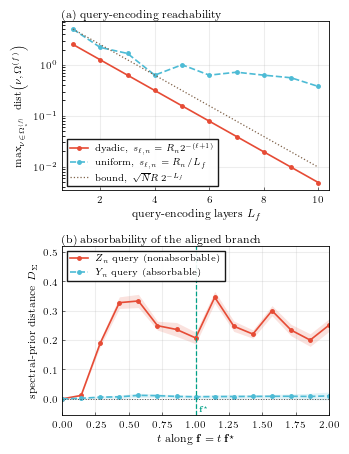

saved /home/felix/SAR-QML/notebooks/fig_alignment_single.pdf

summary
  (a) T=6: dyadic 7.854e-02  uniform 6.283e-01  bound 1.571e-01
      ratio uniform/dyadic: T=4 2.0  T=10 76.8
  (b) N=1600, 10 jackknife blocks
      aligned  raw 0.3886 -> corrected 0.3454 +- 0.0102
      control  raw 0.0810 -> corrected 0.0119 +- 0.0037
      control |D|/SE: max 3.70, median 2.63


In [5]:
r"""Single-column theory figure: structural alignment of a DDR circuit with an
MNUDFT task.

(a) The query encoding can make the task modes accessible. Direct verification
    of Theorem 1.

(b) The aligned query branch is not absorbable. Jackknife bias-corrected
    D_Sigma along the ray f = t f^*, for the aligned Z_e query and for a Y_e
    control with identical generator eigenvalues, hence identical Omega^(f),
    which commutes with the R_y trainable generators and is therefore absorbed.

The raw estimator of D_Sigma is biased upward at finite N: Sigma(f) and
Sigma(0) are both norm-inflated by sampling noise, and the norms enter the
denominator of a normalized alignment, so the alignment is biased below one
even when the two populations coincide. The bias is O(1/N) and is removed by a
delete-a-block jackknife, using the same block deletion for Sigma(f) and
Sigma(0) since they share the parameter ensemble. After correction the
absorbable control is consistent with zero, which is what Proposition 7
predicts and what the uncorrected estimator obscures.
"""

import os
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# import alignment as al

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "axes.linewidth": 0.6,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "legend.fontsize": 6.5,
    "lines.linewidth": 1.2,
})

# =============================================================================
# PRX Quantum manuscript figure: two stacked panels
# =============================================================================
COLORS = {
    "aligned": "#E64B35",
    "control": "#4DBBD5",
    "bound": "#7E6148",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}
LABELS = {
    "dyadic": r"dyadic, $s_{\ell,n}=R_n2^{-(\ell+1)}$",
    "uniform": r"uniform, $s_{\ell,n}=R_n/L_f$",
    "bound": r"bound, $\sqrt{N}R\,2^{-L_f}$",
    "aligned": r"$Z_n$ query (nonabsorbable)",
    "control": r"$Y_n$ query (absorbable)",
}

OUTDIR = Path(".")
LAYER_RANGE = np.arange(1, 11)
RAY = np.linspace(0.0, 2.0, 15)
ENSEMBLE = 1600
BLOCKS = 10

print("panel (a) ...")
dyadic_error = np.array([coverage_error(t, "dyadic") for t in LAYER_RANGE])
uniform_error = np.array([coverage_error(t, "uniform") for t in LAYER_RANGE])
bound = (
    np.sqrt(NUMBER_OF_QUERIES) * COORDINATE_EXTENT
    * 2.0 ** (-LAYER_RANGE.astype(float))
)

print("panel (b) ...")
scales = generator_scales(NUMBER_OF_LAYERS, "dyadic")
CACHE = "panel_b_cache.npz"
if os.path.exists(CACHE):
    cached = np.load(CACHE)
    aligned, aligned_error, aligned_raw = (
        cached["aligned"], cached["aligned_error"], cached["aligned_raw"]
    )
    control, control_error, control_raw = (
        cached["control"], cached["control_error"], cached["control_raw"]
    )
    print("  loaded from cache")
else:
    aligned, aligned_error, aligned_raw = jackknife_prior_distance(
        RAY, scales, "Z", np.random.default_rng(11), ENSEMBLE, BLOCKS
    )
    print("  aligned done")
    control, control_error, control_raw = jackknife_prior_distance(
        RAY, scales, "Y", np.random.default_rng(11), ENSEMBLE, BLOCKS
    )
    print("  control done")
    np.savez(
        CACHE, aligned=aligned, aligned_error=aligned_error,
        aligned_raw=aligned_raw, control=control,
        control_error=control_error, control_raw=control_raw,
    )

fig = plt.figure(figsize=(3.375, 4.45), layout="constrained")
fig.get_layout_engine().set(h_pad=0.05, hspace=0.06)
axes = fig.subplots(2, 1)

# (a) reachability of the task modes under the query encoding
axis = axes[0]
axis.semilogy(
    LAYER_RANGE,
    dyadic_error,
    color=COLORS["aligned"],
    marker="o",
    ms=2.5,
    label=LABELS["dyadic"],
)
axis.semilogy(
    LAYER_RANGE,
    uniform_error,
    color=COLORS["control"],
    marker="o",
    ms=2.5,
    ls="--",
    label=LABELS["uniform"],
)
axis.semilogy(
    LAYER_RANGE,
    bound,
    color=COLORS["bound"],
    lw=0.9,
    ls=":",
    label=LABELS["bound"],
)
axis.set_xlim(0.6, 10.4)
axis.set_xticks([2, 4, 6, 8, 10])
axis.set_xlabel(r"query-encoding layers $L_f$")
axis.set_ylabel(
    r"$\max_{\nu\in\Omega^{(f)}_\star}\ \mathrm{dist}\!\left(\nu,\Omega^{(f)}\right)$",
    fontsize=7.4,
)
axis.set_title("(a) query-encoding reachability", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    frameon=True,
        framealpha=0.9,
        edgecolor="black",
        fancybox=False,
    loc="lower left",
)

# (b) bias-corrected spectral-prior distance along the aligned ray
axis = axes[1]
for arm, values, errors in (
    ("aligned", aligned, aligned_error),
    ("control", control, control_error),
):
    axis.fill_between(
        RAY,
        values - 1.96 * errors,
        values + 1.96 * errors,
        color=COLORS[arm],
        alpha=0.16,
        linewidth=0,
    )
    axis.plot(
        RAY,
        values,
        color=COLORS[arm],
        marker="o",
        ms=2.5,
        ls="-" if arm == "aligned" else "--",
        label=LABELS[arm],
    )
axis.axhline(0.0, color=COLORS["reference"], ls=":", lw=0.7)
axis.axvline(1.0, color=COLORS["geometry"], ls="--", lw=0.9)
upper = float((aligned + 1.96 * aligned_error).max())
axis.set_xlim(0.0, 2.0)
axis.set_ylim(-0.055, upper * 1.42)
axis.annotate(
    r"$\mathbf{f}^\star$",
    xy=(1.0, axis.get_ylim()[0]),
    xytext=(2.5, 2.0),
    textcoords="offset points",
    color=COLORS["geometry"],
    fontsize=6.0,
    va="bottom",
)
axis.set_xlabel(r"$t$ along $\mathbf{f}=t\,\mathbf{f}^\star$")
axis.set_ylabel(r"spectral-prior distance $D_\Sigma$", fontsize=7.4)
axis.set_title("(b) absorbability of the aligned branch", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)

figure_stem = OUTDIR / "fig_alignment_single"
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {figure_stem.with_suffix('.pdf').resolve()}")

print("\nsummary")
print(f"  (a) T=6: dyadic {dyadic_error[5]:.3e}  uniform {uniform_error[5]:.3e}"
      f"  bound {bound[5]:.3e}")
print(f"      ratio uniform/dyadic: T=4 {uniform_error[3]/dyadic_error[3]:.1f}"
      f"  T=10 {uniform_error[-1]/dyadic_error[-1]:.1f}")
print(f"  (b) N={ENSEMBLE}, {BLOCKS} jackknife blocks")
print(f"      aligned  raw {aligned_raw.max():.4f} -> corrected "
      f"{aligned.max():.4f} +- {aligned_error[np.argmax(aligned)]:.4f}")
print(f"      control  raw {control_raw.max():.4f} -> corrected "
      f"{control.max():.4f} +- {control_error[np.argmax(control)]:.4f}")
significance = np.abs(control) / np.maximum(control_error, 1e-12)
print(f"      control |D|/SE: max {significance.max():.2f}, "
      f"median {np.median(significance):.2f}")

In [6]:
stop

NameError: name 'stop' is not defined


summary
  (a) T=6: dyadic 7.854e-02  uniform 6.283e-01  bound 1.571e-01
      ratio uniform/dyadic: T=4 2.0  T=10 76.8
  (b) N=1600, 10 jackknife blocks
      aligned  raw 0.3886 -> corrected 0.3454 +- 0.0102
      control  raw 0.0810 -> corrected 0.0119 +- 0.0037
      control |D|/SE: max 3.70, median 2.63
figure written


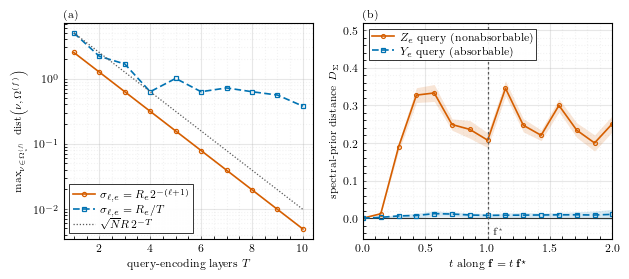

In [ ]:
figure, axes = plt.subplots(1, 2, figsize=(7.08, 2.50))



# ---------------------------------------------------------------- (a)
axis = axes[0]
axis.semilogy(LAYER_RANGE, dyadic_error, color=ALIGNED, marker="o",
              markersize=3.0, markerfacecolor="none", markeredgewidth=0.9,
              label=r"$\sigma_{\ell,e}=R_e2^{-(\ell+1)}$")
axis.semilogy(LAYER_RANGE, uniform_error, color=CONTROL, marker="s",
              markersize=3.0, markerfacecolor="none", markeredgewidth=0.9,
              ls=(0, (4, 2)), label=r"$\sigma_{\ell,e}=R_e/T$")
axis.semilogy(LAYER_RANGE, bound, color=REFERENCE, lw=0.9, ls=(0, (1, 1.5)),
              label=r"$\sqrt{N}R\,2^{-T}$")
axis.set_xlabel(r"query-encoding layers $T$")
axis.set_ylabel(
    r"$\max_{\nu\in\Omega^{(f)}_\star}\ \mathrm{dist}\!\left(\nu,\Omega^{(f)}\right)$",
    fontsize=7.4,
)
axis.set_xlim(0.6, 10.4)
axis.set_xticks([2, 4, 6, 8, 10])
axis.legend(loc="lower left", frameon=True, framealpha=0.92,
            edgecolor="black", fancybox=False, borderpad=0.3,
            handletextpad=0.5, labelspacing=0.25)
axis.get_legend().get_frame().set_linewidth(0.6)
axis.set_title("(a)", loc="left", pad=4, fontweight="bold")
style(axis)

# ---------------------------------------------------------------- (b)
axis = axes[1]
axis.axhline(0.0, color="0.2", lw=0.8)
axis.plot(RAY, aligned, color=ALIGNED, ls="-", marker="o", markersize=2.8,
          markerfacecolor="none", markeredgewidth=0.9,
          label=r"$Z_e$ query (nonabsorbable)")
axis.fill_between(RAY, aligned - 1.96 * aligned_error,
                  aligned + 1.96 * aligned_error,
                  color=ALIGNED, alpha=0.16, linewidth=0)
axis.plot(RAY, control, color=CONTROL, ls=(0, (4, 2)), marker="s",
          markersize=2.8, markerfacecolor="none", markeredgewidth=0.9,
          label=r"$Y_e$ query (absorbable)")
axis.fill_between(RAY, control - 1.96 * control_error,
                  control + 1.96 * control_error,
                  color=CONTROL, alpha=0.16, linewidth=0)
axis.axvline(1.0, color=REFERENCE, lw=0.9, ls=(0, (2, 2)))
axis.set_xlabel(r"$t$ along $\mathbf{f}=t\,\mathbf{f}^\star$")
axis.set_ylabel(r"spectral-prior distance $D_\Sigma$", fontsize=7.4)
axis.set_xlim(0.0, 2.0)
upper = (aligned + 1.96 * aligned_error).max()
axis.set_ylim(-0.055, upper * 1.42)
axis.text(1.045, -0.042, r"$\mathbf{f}^\star$", fontsize=7.2,
          color=REFERENCE)
axis.legend(loc="upper left", frameon=True, framealpha=0.92,
            edgecolor="black", fancybox=False, borderpad=0.3,
            handletextpad=0.5, labelspacing=0.25)
axis.get_legend().get_frame().set_linewidth(0.6)
axis.set_title("(b)", loc="left", pad=4, fontweight="bold")
style(axis)

figure.subplots_adjust(left=0.200, right=0.975, bottom=0.092, top=0.955,
                       hspace=0.40)
figure.savefig("fig_alignment_single.pdf", pad_inches=0.05,bbox_inches='tight')
figure.savefig("fig_alignment_single.png", dpi=600, pad_inches=0)

print("\nsummary")
print(f"  (a) T=6: dyadic {dyadic_error[5]:.3e}  uniform {uniform_error[5]:.3e}"
      f"  bound {bound[5]:.3e}")
print(f"      ratio uniform/dyadic: T=4 {uniform_error[3]/dyadic_error[3]:.1f}"
      f"  T=10 {uniform_error[-1]/dyadic_error[-1]:.1f}")
print(f"  (b) N={ENSEMBLE}, {BLOCKS} jackknife blocks")
print(f"      aligned  raw {aligned_raw.max():.4f} -> corrected "
      f"{aligned.max():.4f} +- {aligned_error[np.argmax(aligned)]:.4f}")
print(f"      control  raw {control_raw.max():.4f} -> corrected "
      f"{control.max():.4f} +- {control_error[np.argmax(control)]:.4f}")
significance = np.abs(control) / np.maximum(control_error, 1e-12)
print(f"      control |D|/SE: max {significance.max():.2f}, "
      f"median {np.median(significance):.2f}")
print("figure written")